In [1]:
# =========================
# 1. Install Dependencies
# =========================

# torch-geometric (CPU-safe, no torch-cluster required)
!pip install -q torch-geometric
!pip install -q pymatgen pandas scikit-learn matplotlib scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 2.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.1/829.1 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 89.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 88.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.5/962.5 kB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 9.5 MB/s eta 0:00:00
ERROR: pip'

In [2]:
# =========================
# 2. Imports
# =========================

import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from google.colab import files

import torch
from torch import nn
from torch.optim import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from pymatgen.core import Structure

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SchNet

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch version: 2.10.0+cu128
CUDA available: True


In [6]:
# =========================
# 5. Configuration
# =========================


CUTOFF_RADIUS = 6.0   # Angstroms

BATCH_SIZE   = 32
LR           = 0.001
EPOCHS       = 100
RANDOM_STATE = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [4]:
# =========================
# graph input
# =========================

from google.colab import files
uploaded = files.upload()  # upload heusler_schnet_graphs.pt

import torch
dataset = torch.load("heusler_schnet_graphs.pt", map_location="cpu", weights_only=False)
print("Loaded. Total graphs:", len(dataset))

Saving heusler_schnet_graphs.pt to heusler_schnet_graphs (1).pt
Loaded. Total graphs: 8166


In [12]:
# =========================
# Train / Val / Test Split  (0.8 / 0.1 / 0.1)
# =========================

train_data, temp_data = train_test_split(
    dataset, test_size=0.2, random_state=RANDOM_STATE
)

val_data, test_data = train_test_split(
    temp_data, test_size=0.5, random_state=RANDOM_STATE
)

print(f"Train: {len(train_data)} | Val: {len(val_data)} | Test: {len(test_data)}")

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_data,   batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_data,  batch_size=BATCH_SIZE)

Train: 6532 | Val: 817 | Test: 817


In [23]:
# =========================
# Build SchNet Model (no torch-cluster)
# =========================

from torch_geometric.nn import SchNet
from torch_geometric.nn import global_add_pool

class SchNetNoCluster(SchNet):
    def forward(self, z, pos, batch, edge_index):
        h = self.embedding(z)

        row, col = edge_index
        diff = pos[row] - pos[col]
        dist = diff.norm(dim=-1)

        edge_attr = self.distance_expansion(dist)

        for interaction in self.interactions:
            h = h + interaction(h, edge_index, dist, edge_attr)  # x, edge_index, edge_weight, edge_attr

        h = self.lin1(h)
        h = self.act(h)
        h = self.lin2(h)

        out = global_add_pool(h, batch)
        return out.squeeze(-1)

model = SchNetNoCluster(
    hidden_channels=128,
    num_filters=128,
    num_interactions=6,
    num_gaussians=50,
    cutoff=6.0
).to(DEVICE)

optimizer = Adam(model.parameters(), lr=LR)
criterion = nn.MSELoss()

print(model)

SchNetNoCluster(hidden_channels=128, num_filters=128, num_interactions=6, num_gaussians=50, cutoff=6.0)


In [25]:
# =========================
# Training Loop
# =========================

best_val_loss = float("inf")
train_losses  = []
val_losses    = []

for epoch in range(EPOCHS):

    # ── TRAIN ──
    model.train()
    total_loss = 0

    for batch in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()

        pred = model(
            z=batch.z,
            pos=batch.pos,
            batch=batch.batch,
            edge_index=batch.edge_index
        )

        loss = criterion(pred.squeeze(), batch.y.squeeze())
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    train_loss = total_loss / len(train_loader)
    train_losses.append(train_loss)

    # ── VALIDATION ──
    model.eval()
    val_total = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = batch.to(DEVICE)
            pred = model(
                z=batch.z,
                pos=batch.pos,
                batch=batch.batch,
                edge_index=batch.edge_index
            )
            loss = criterion(pred.squeeze(), batch.y.squeeze())
            val_total += loss.item()

    val_loss = val_total / len(val_loader)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1:03d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "schnet_trained_best.pt")

print("Training complete. Best val loss:", round(best_val_loss, 4))

Epoch 001/100 | Train Loss: 4.6674 | Val Loss: 1.6856
Epoch 002/100 | Train Loss: 0.8471 | Val Loss: 0.8642
Epoch 003/100 | Train Loss: 0.5851 | Val Loss: 2.9986
Epoch 004/100 | Train Loss: 0.6667 | Val Loss: 0.7056
Epoch 005/100 | Train Loss: 0.4423 | Val Loss: 0.6853
Epoch 006/100 | Train Loss: 0.4411 | Val Loss: 0.4142
Epoch 007/100 | Train Loss: 0.4846 | Val Loss: 0.5118
Epoch 008/100 | Train Loss: 0.3948 | Val Loss: 0.6343
Epoch 009/100 | Train Loss: 0.4100 | Val Loss: 0.4044
Epoch 010/100 | Train Loss: 0.3490 | Val Loss: 1.2932
Epoch 011/100 | Train Loss: 0.3974 | Val Loss: 0.4479
Epoch 012/100 | Train Loss: 0.3832 | Val Loss: 0.3290
Epoch 013/100 | Train Loss: 0.2491 | Val Loss: 0.2545
Epoch 014/100 | Train Loss: 0.2734 | Val Loss: 0.3436
Epoch 015/100 | Train Loss: 0.2048 | Val Loss: 0.3506
Epoch 016/100 | Train Loss: 0.2082 | Val Loss: 0.2614
Epoch 017/100 | Train Loss: 0.3961 | Val Loss: 0.3208
Epoch 018/100 | Train Loss: 0.3602 | Val Loss: 0.2592
Epoch 019/100 | Train Loss: 

In [26]:
# =========================
# Evaluation on Test Set
# =========================

model.load_state_dict(torch.load("schnet_trained_best.pt", map_location=DEVICE))
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(DEVICE)
        pred = model(
            z=batch.z,
            pos=batch.pos,
            batch=batch.batch,
            edge_index=batch.edge_index
        )
        y_true.extend(batch.y.cpu().numpy().flatten())
        y_pred.extend(pred.cpu().numpy().flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

mae  = mean_absolute_error(y_true, y_pred)
mse  = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_true, y_pred)

print("\n=== SchNet Test Results ===")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")


=== SchNet Test Results ===
MAE  : 0.2091
MSE  : 0.1037
RMSE : 0.3220
R²   : 0.9273


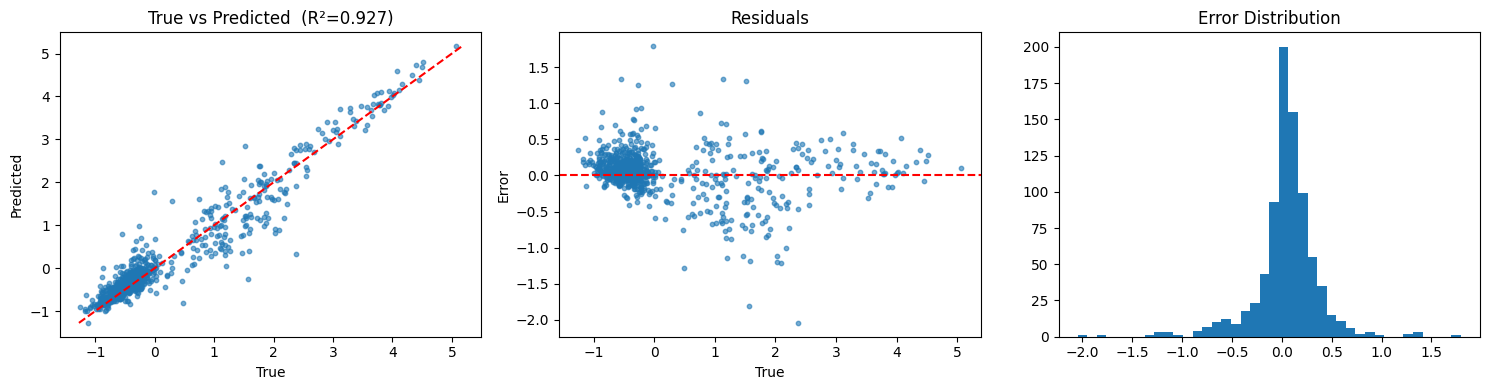

Plots saved.


In [27]:
# =========================
# Diagnostic Plots
# =========================

errors = y_pred - y_true

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Parity plot
axes[0].scatter(y_true, y_pred, alpha=0.6, s=10)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--')
axes[0].set_xlabel("True")
axes[0].set_ylabel("Predicted")
axes[0].set_title(f"True vs Predicted  (R²={r2:.3f})")

# Residuals
axes[1].scatter(y_true, errors, alpha=0.6, s=10)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel("True")
axes[1].set_ylabel("Error")
axes[1].set_title("Residuals")

# Error distribution
axes[2].hist(errors, bins=40)
axes[2].set_title("Error Distribution")

plt.tight_layout()
plt.savefig("schnet_results.png", dpi=300, bbox_inches="tight")
plt.show()
print("Plots saved.")

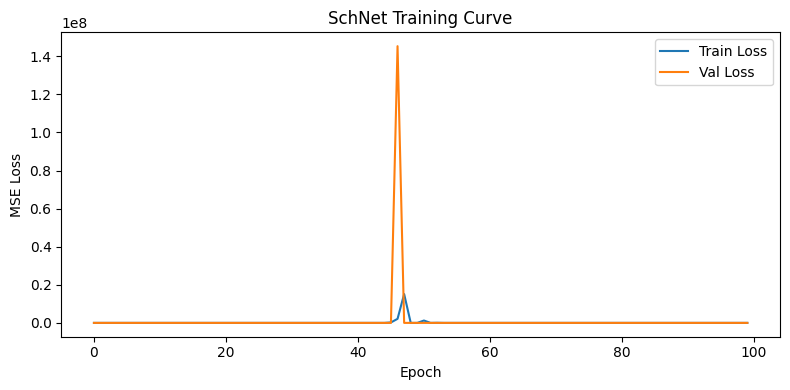

Loss curve saved.


In [28]:
# =========================
# Loss Curve
# =========================

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses,   label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("SchNet Training Curve")
plt.legend()
plt.tight_layout()
plt.savefig("schnet_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()
print("Loss curve saved.")

In [29]:
# =========================
# Save Results JSON
# =========================

results = {
    "mae" : float(mae),
    "mse" : float(mse),
    "rmse": float(rmse),
    "r2"  : float(r2)
}

with open("schnet_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Results saved to schnet_results.json")

Results saved to schnet_results.json


In [30]:
# =========================
#  Download Outputs
# =========================

files.download("schnet_trained_best.pt")
files.download("schnet_results.json")
files.download("schnet_results.png")
files.download("schnet_loss_curve.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>